# conv_01 — 컨베이어 센서: 구조 · 추출 데이터 · 그룹 연결 (로직맵)

컨베이어 센서 이상 탐지 모델의 **첫 노트북**이다. 여기서는 모델을 만들지 않는다. 다음 세 가지를 정리하고 데이터로 확인한다.

1. **어떤 데이터를 뽑았나** — 기간, 캐시 위치, 그룹별 태그 (§0-2, §0-3)
2. **그룹이 서로 어떻게 이어지나** — 유닛 내부 / 기준 센서끼리 / 라인 전체 3단 구조 (§0-4)
3. **왜 시간이 아니라 카운트로 보나** — DB 샘플링 한계와 PLC 카운터로 엣지를 복원하는 원리 (§0-1, §3, §4)

| 자료 | 위치 |
|---|---|
| PLC 로직 | `IL/IL_file/Preparation.il` (카운터·대차번호·존 체크), `Air_Supply_Unit.il` (전진·후진·에어백 유닛), `금형CY_번호인식.il` (전진·후진 대차번호) |
| 팀 정리 | `z현대공업/컨베이어센서/Air_Supply2_정상사이클.xlsx` (전진 유닛 정상 사이클 9단계) |
| 센서 위치 | `kta 자료_센서위치.pdf` |
| 태그 정의 | `Conv/conv_tags.py` |
| 추출기 | `Conv/extract_conv_cache.py` |
| 공용 함수 | `Conv/conv_core.py` (절대 위치 · 카운터 리셋 · 원본 엣지) |

---
## §0. 정리

### 0-1. 왜 시간이 아니라 카운트인가

**DB 는 약 0.5초마다, 값이 바뀐 태그만 기록한다.** 컨베이어 센서는 대차가 지나가는 순간만 켜지는 짧은 펄스라서 원본 비트로는 자주 놓친다.

- 10/19 14–15시(정상 가동) 실측: 대차는 276대 지나갔는데 클로징 존 진입 감지(P00154)의 상승엣지는 DB 에 **165번만** 남았다.
- 엔코더(P00143/P00144)는 40.5 Hz 운전에서 초당 약 11펄스(약 90ms 간격)라서 원본 비트는 아예 쓸 수 없다.

**대신 PLC 의 존 카운터가 모든 엣지를 기억한다.** 각 존 카운터(R000xx)는 엔코더 펄스마다 +1 되고, 그 존의 진입 센서가 켜지는 순간 1로 리셋된다. 카운터는 매 샘플 바뀌므로 DB 에 빠짐없이 남는다.

| 시각 | 클로징 진입 센서 P00154 (DB 값) | 클로징 카운터 R00030 (DB 값) | 해석 |
|---|---|---|---|
| 10.0초 | 0 | 137 | |
| 10.5초 | 0 ← 켜졌다 꺼진 걸 놓침 | 4 | 137 → 4 로 떨어졌으니 그 사이 센서가 켜졌다. **4 − 1 = 3카운트 전**에 켜졌다 |

- 같은 1시간 동안 카운터 리셋은 **276번 모두** 잡혔다 (= 대차 수).
- 이것이 "래치 대신 카운트"의 뜻이다. 래치값을 따로 찾을 필요 없이, 카운터가 센서 엣지의 흔적을 남긴다.
- **한계:** 카운터가 연결된 **기준 센서 6개**에만 통한다. 나머지 센서(스톱퍼 감지, 정위치 등)는 기준 카운터 대비 위치로 표현하며 ±0.5초(약 ±6카운트) 오차가 있다. 그래서 개별 판정보다 **분포와 추세**로 본다.

**카운트 축의 장점**
- 위치(거리)로 정의되므로 속도가 바뀌어도 값이 같다. 속도 정규화가 필요 없다.
- 속도는 따로 건강 지표가 된다: `초당 카운트 ÷ (Hz_In_Conv/10) = 0.2744` (09-10 – 10-19 가동 31일, 일별 흔들림 ±0.0001, 324–405 전 속도에서 같음 — §5). 이 비율이 변하면 구동부(인버터·체인 미끄러짐) 문제다.
- 대차 간격(피치)은 **139카운트**다. 42대 × 139 = 한 바퀴 약 5,838카운트.

### 0-2. 추출 데이터

| 항목 | 내용 |
|---|---|
| 기간 | **2026-09-10 – 2026-10-19** (09-09 15:53 에 수집 태그 집합이 바뀌어서 09-10 부터) |
| 저장 | `cache/conv_raw/{그룹}/{YYYY-MM-DD}.pkl.xz` — 그룹별 하루 한 파일, 약 0.5 MB |
| 형식 | 원래 타임스탬프 그대로(약 0.5초, **리샘플 없음**), ffill, 인덱스는 naive KST, 값은 PLC 정수(float32) |
| 다시 받기 | `python Conv/extract_conv_cache.py --start 2026-10-20 --end 2026-10-25` (이미 받은 날은 건너뜀) |
| 현황 | `python Conv/extract_conv_cache.py --status` |
| 읽기 | `load_group("md_fwd", "2026-10-16")` 또는 `load_group("md_fwd", "2026-10-01", "2026-10-07")` |

**모든 그룹 파일에 공통으로 넣은 태그 (COMMON)** — 그룹 파일 하나만 열어도 운전 구간·속도·대차번호·위치를 알 수 있게 했다.

| 태그 | 뜻 |
|---|---|
| Conv_Run_Out | 컨베이어 운전 출력 (분석 구간 마스크) |
| Hz_In_Conv | 속도 지령 (0.1 Hz 단위, 405 = 40.5 Hz) |
| Now_Actual_Wagon_Num | 메인 대차번호 1–42 |
| R00030, R00040 | 클로징·주입부 카운터 (절대 위치를 만드는 눈금) |

**그룹 7개**

| 그룹 | 위치 | 기준 센서 → 카운터 | 태그 수 | 담긴 것 |
|---|---|---|---|---|
| `main` | 구동부 + 주입부 | 대차 진입 감지 P00140 → R00040, 대차 쉬프트 감지 P00141 → R00080 | 47 | 엔코더, 1번 대차 감지, 인버터·브레이크·트립, 정지·감속 상태, 대차 Dog 에러, 피치 최대/최소 |
| `opening` | 왼쪽 회전부 | 오프닝 존 진입 감지 P00164 → R00070 | 38 | 리프트 리밋 4개, 오버트래블, 모터 정/역·브레이크, 동작 시점 설정값, 에러 |
| `closing` | 오른쪽 회전부 | 클로징 존 진입 감지 P00154 → R00030 | 37 | 오프닝과 같은 구성 |
| `md_fwd` | 전진 유닛 | 전진 진입 감지 P00451 → R00055 | 42 | 정위치·끝단·비상·스톱퍼·노즐 감지, SOL 출력 4개, 시퀀스 내부 비트, 에러 7개 |
| `md_rev` | 후진 유닛 | 후진 진입 감지 P00459 → R00060 | 42 | 전진 유닛과 같은 구성 |
| `airbag` | 에어백 유닛 #1 | (진입 센서 P00130 은 PLC 에서 꺼져 있음, 클로징 센서 공유 → R00050) | 29 | 사용 여부 확인용 |
| `tension` | 체인 텐션·안전 | — | 19 | 체인 텐션 리미트, 텐션 유압, 와이어 스위치 (장기 추세·마스킹용) |

### 0-3. 센서 표

★ = 기준 센서(카운터가 연결되어 엣지를 정확히 복원할 수 있는 센서)

**① 구동부 (`main`)**

| 이름 | 주소 | 하는 일 |
|---|---|---|
| 컨베이어 엔코더 A / B | P00143 / P00144 | 체인 이동량 펄스. 모든 카운터의 눈금. A·B 위상으로 정/역회전 판별 |
| 컨베이어 운전 출력 | Conv_Run_Out | 운전 중 여부 |
| 속도 지령 | Hz_In_Conv | 인버터 속도 |
| 인버터 정회전 / 역회전 / 속도 / 리셋 | P0021C / P0021D / P0021E / P0021F | 구동 출력 |
| 컨베이어 브레이크 / 트립 | P0025D / P0003A | |

**② 주입부 대차 감지 (`main`)**

| 이름 | 주소 | 하는 일 | 카운터 |
|---|---|---|---|
| ★ 대차 진입 감지 | P00140 | 대차 표식(dog) 감지 → 대차번호 +1 | R00040 |
| ★ 대차 쉬프트 감지 | P00141 | 정지 위치 계산용 | R00080 |
| 1번 대차 감지 | P00142 | 1번 대차 표식 → 대차번호를 1로 | |

**③ 오프닝 존 (`opening`) / ⑥ 클로징 존 (`closing`)** — 같은 구조, 회전부에서 금형 리프트를 올리고 내린다

| 이름 | 오프닝 | 클로징 | 하는 일 |
|---|---|---|---|
| ★ 존 진입 감지 | P00164 (R00070) | P00154 (R00030) | 카운터 리셋 → 카운터 값으로 리프트 하강·상승 시점 결정 |
| 리프트 상승정지 / 상승감속 | P00160 / P00161 | P00150 / P00151 | 리프트 위치 리밋 |
| 리프트 하강감속 / 하강정지 | P00162 / P00163 | P00152 / P00153 | |
| 오버트래블 상승 / 하강 | P00165 / P00166 | P00155 / P00156 | 과이동 에러 |
| 비상 감지 | P0016E | P0015E | |
| 리프트 모터 정 / 역 / 브레이크 | P00218 / P00219 / P0025F | P00214 / P00215 / P0025E | 출력 |

**④ 전진 유닛 (`md_fwd`) / ⑤ 후진 유닛 (`md_rev`)** — 같은 구조, 중형 금형 CY 에 에어 주입

| 이름 | 전진 | 후진 |
|---|---|---|
| 1번 대차 감지 | P00450 | P00458 |
| ★ 진입 감지 | P00451 (R00055) | P00459 (R00060) |
| 정위치 감지 | P00452 | P0045A |
| 끝단 후진 감지 | P00453 | P0045B |
| 비상 감지 (오버트래블) | P00454 | P0045C |
| 스톱퍼 전진 감지 / 후진 감지 | P00455 / P00456 | P0045D / P0045E |
| 노즐 후진 감지 (노즐 1·2 공용 입력) | P00457 | P0045F |
| 출력: 스톱퍼 SOL | P00470 | P00474 |
| 출력: 노즐 전후진 SOL | P00471 | P00475 |
| 출력: 원점복귀 SOL | P00472 | P00476 |
| 출력: 노즐 오픈 SOL | P00473 | P00477 |

**⑦ 체인 텐션 (`tension`)**: 체인 텐션 리미트 P0006F, 텐션 유압 저압 P0006E, 텐션 유압 트립 P0003D, 텐션 유압 MC P00250, 와이어 스위치 P0015F

### 0-4. 그룹은 어떻게 이어지나

모든 센서는 **엔코더 하나가 도는 같은 체인 위에** 있다. 그래서 모든 카운터는 같은 눈금을 쓰고, 그 눈금으로 전부 이어 볼 수 있다.

```
                       엔코더 A/B (P00143/P00144) — 펄스마다 모든 존 카운터 +1
                                          │
       ┌──────────────┬──────────────┬────┴─────────┬──────────────┬──────────────┐
       ▼              ▼              ▼              ▼              ▼              ▼
  ★대차 진입      ★대차 쉬프트     ★오프닝 진입    ★전진 진입      ★후진 진입     ★클로징 진입
   P00140          P00141          P00164          P00451          P00459          P00154
   R00040          R00080          R00070          R00055          R00060          R00030
   │                               │               │               │               │
   대차번호 +1                      리프트 하강/상승  스톱퍼→노즐→     (전진과 동일)    리프트 하강/상승
   (P00142: 1로)                    (P00160–163)    오픈→복귀                       (P00150–153)
                                                   (P00452–457)
  └─────────────── 2단: 기준 센서끼리 거리 = 고정값 (같은 대차들이 지나가므로) ───────────────┘
                               3단: 대차 한 대가 한 바퀴 동안 위 센서를 차례로 지나감
```

| 단계 | 무엇끼리 | 무엇을 보나 | 이상이면 |
|---|---|---|---|
| **1단: 유닛 내부** | 한 유닛 안의 센서·출력 (예: 전진 진입 → 스톱퍼 전진 → 정위치 OFF → 노즐 전진 → 오픈 → 끝단 후진 → 복귀) | 순서와 간격이 정상 시퀀스대로인지 (기준 카운터 대비 위치) | 그 유닛의 실린더·센서 문제 |
| **2단: 기준 센서끼리** | ★ 6개 | 센서 간 거리가 항상 일정한지. 예: 클로징 → 주입부 121카운트 (흔들림 3.7) | 하나만 어긋나면 그 센서, 전부 같이 어긋나면 컨베이어 자체 |
| **3단: 라인 전체 (대차별)** | 대차 한 대가 지나는 모든 센서 | 대차별 지문(피치)과 바퀴별·일별 추세 | 특정 대차 문제 vs 라인 전체 노후 |

1단은 유닛을 단독으로 본다. 2·3단이 유닛들을 서로 잇는다. 최종 판정은 **센서 이상 / 대차 이상 / 컨베이어 전체 이상**의 3단이다.

**유닛 내부 시퀀스는 PLC 가 카운터 값으로 트리거한다** (설정값은 DB 에서 확인).

| 유닛 | 트리거 | 설정값 |
|---|---|---|
| 전진 유닛 | R00055 가 30–33 구간에 들어가면 스톱퍼 전진 | R00056 = 30 |
| 후진 유닛 | R00060 이 27–30 구간 | R00061 = 27 |
| 클로징 리프트 | 상승 확인 / 하강 시작 / 하강 확인 / 상승 시작 | R00031 = 9 / R00032 = 42 / R00033 = 80 / R00034 = 105 |
| 오프닝 리프트 | 하강 확인 / 상승 시작 / 상승 확인 / 하강 시작 | R00073 = 5 / R00074 = 24 / R00071 = 59 / R00072 = 87 |
| 존 미감지 에러 | 어떤 존 카운터든 160 에 닿으면 (진입 센서가 대차를 놓친 것) | R00067 = 160 |

### 0-5. 대차번호는 믿을 수 있나

**결론: 메인 대차번호(Now_Actual_Wagon_Num)는 물리적 대차와 묶여 있다.**

- **구조:** 1번 대차 감지 센서(P00142)는 라인에 고정돼 있고, 1번 대차에만 붙은 표식을 본다. 표식이 대차를 따라다니므로 번호가 대차에 묶인다.
- **데이터 (10/19 06–09시, 18바퀴):** 매번 42 다음에 1로 넘어갔다. 1번 대차 인식 에러 0회, 수동 대차번호 변경 0회.
- **번호와 무관한 물리적 지문:** 대차별 피치가 대부분 139카운트인데 **연속 6대만 142–143카운트**다. 같은 대차 안 흔들림은 0.2–0.4, 바퀴 간 패턴 상관은 0.95. 그래서 번호가 밀려도 지문으로 검증할 수 있다.
- **주의:** 전진/후진 유닛의 대차번호 태그(전진_Actual_Wagon_Num 등)는 3시간에 몇 줄만 기록됐다. 메인 번호 + 고정 오프셋으로 계산한다 (conv_02).
- **주의:** 대차번호는 주입부(P00140)에서 바뀌므로, 다른 센서가 켜진 순간의 번호는 "그 센서 앞에 있는 대차"가 아니라 "주입부에 있는 대차"다. 센서별 오프셋은 conv_02 에서 지문으로 맞춘다.

### 0-6. 가설과 진행 계획

| 가설 | 내용 | 볼 곳 |
|---|---|---|
| **H1** | 기준 센서 6개는 모든 대차 엣지를 남긴다 (카운터 리셋 수 = 대차 수). 원본 비트는 많이 놓친다 | 이 노트북 §4 |
| **H2** | 기준 센서의 피치는 139카운트로 안정적이다. 흔들림이 큰 센서는 이상 후보 | §5 (미리보기), conv_03 |
| **H3** | 속도 비율(초당 카운트 ÷ Hz/10)은 기간 내내 일정하다 | §5 |
| **H4** | 대차 지문(피치 패턴)은 기간 내내 고정이다 → 대차번호 검증 가능 | conv_02 |
| **H5** | 전진 진입 감지(P00451)의 피치 흔들림(1시간 std 9.3)은 센서 쪽 문제다 (대차 의존이 아니다) | conv_02, conv_03 |

| 노트북 | 내용 |
|---|---|
| **conv_01** (이것) | 구조·데이터 정리, 캐시 확인, 카운터 원리 확인, 기간 전체 미리보기 |
| conv_02 | 이벤트 복원: 모든 센서 엣지를 "대차번호 × 카운트 위치" 표로. 센서 간 물리 거리, 대차 지문 |
| conv_03 | 정상 분포·추세: 유닛별 시퀀스 분포, 리프트 이동 시간, 피치·속도 비율 일별 추세 |
| conv_04 | 피처·판정: 센서 / 대차 / 컨베이어 3단 판정, 기존 PLC 에러 이력으로 검증 |

---
## §1. 준비

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "Conv" else os.getcwd())
CONV_DIR = os.path.join(ROOT_DIR, "Conv")
for p in (ROOT_DIR, CONV_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore", RuntimeWarning)

from conv_tags import GROUPS, COMMON, ORDER, group_tags
from extract_conv_cache import CACHE_DIR, LOG_PATH, day_path
from conv_core import (load_group, add_position, counter_resets, bit_edges, run_mask, relative_to,
                       COUNTERS, K_SPEED)

START, END = "2026-09-10", "2026-10-19"
DAYS = list(pd.date_range(START, END).strftime("%Y-%m-%d"))
FEAT_DIR = os.path.join(ROOT_DIR, "cache", "conv_feat")
os.makedirs(FEAT_DIR, exist_ok=True)

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
PURPLE, YELLOW = "#7a5cc7", "#c99a06"

#: 기준 센서 6개: (그룹, 카운터, 센서, 이름)
REF_SENSORS = [
    ("main", "R00040", "P00140", "대차 진입"),
    ("main", "R00080", "P00141", "대차 쉬프트"),
    ("opening", "R00070", "P00164", "오프닝 진입"),
    ("closing", "R00030", "P00154", "클로징 진입"),
    ("md_fwd", "R00055", "P00451", "전진 진입"),
    ("md_rev", "R00060", "P00459", "후진 진입"),
]
SENSOR_COLOR = dict(zip([s[3] for s in REF_SENSORS], [INK2, MUTED, AQUA, BLUE, ORANGE, PURPLE]))


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

---
## §2. 캐시 현황

그룹 × 날짜별로 받은 행 수. 비어 있거나 유난히 적은 날은 설비가 쉰 날(일요일·연휴)이거나 수집 공백이다.

In [2]:
log = pd.read_csv(LOG_PATH)
log = log[log.status.isin(["ok", "partial"])].drop_duplicates(["group", "day"], keep="last")
rows = log.pivot(index="group", columns="day", values="rows").reindex(index=ORDER, columns=DAYS)

summary = pd.DataFrame({
    "받은 날": rows.notna().sum(axis=1),
    "빠진 날": rows.isna().sum(axis=1),
    "하루 행수 중앙": rows.median(axis=1).round(),
    "MB": [round(sum(os.path.getsize(day_path(g, d)) for d in DAYS if os.path.exists(day_path(g, d))) / 1e6, 1)
           for g in ORDER],
    "태그 수": [len(group_tags(g)) for g in ORDER],
})
summary

,받은 날,빠진 날,하루 행수 중앙,MB,태그 수
group,,,,,
main,40,0,110378.0,15.0,47
opening,40,0,110182.0,15.0,38
closing,40,0,110180.0,14.1,37
md_fwd,40,0,110193.0,15.9,42
md_rev,40,0,110181.0,15.7,42
airbag,40,0,110176.0,14.2,29
tension,40,0,110180.0,12.5,19


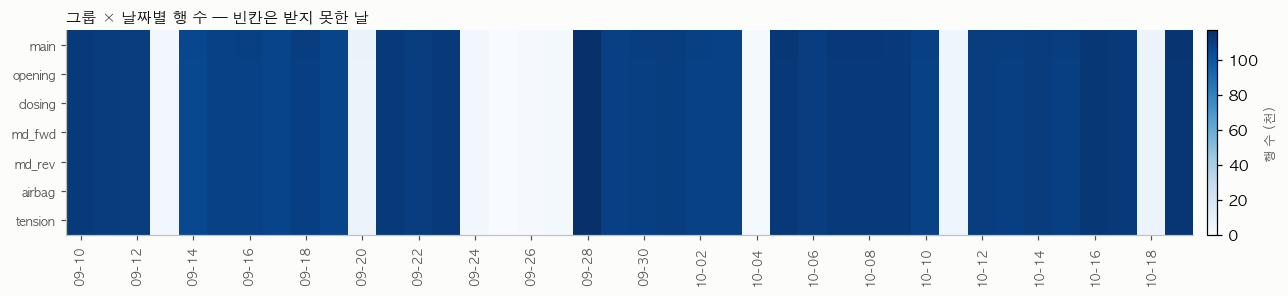

In [3]:
fig, ax = plt.subplots(figsize=(13, 2.8), facecolor=SURFACE)
im = ax.imshow(rows.to_numpy() / 1000, aspect="auto", cmap="Blues", vmin=0)
ax.set_yticks(range(len(ORDER)), ORDER)
ax.set_xticks(range(0, len(DAYS), 2), [d[5:] for d in DAYS[::2]], rotation=90)
style_ax(ax, grid=None)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("행 수 (천)", color=INK2, fontsize=8)
ax.set_title("그룹 × 날짜별 행 수 — 빈칸은 받지 못한 날", color=INK, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

---
## §3. 카운터 원리를 눈으로 확인 — 60초 창

같은 60초 동안 **카운터(톱니)**, **원본 센서 비트**, **카운터로 복원한 엣지(▼)** 를 겹쳐 본다.
원본 비트가 비어 있는 곳에도 카운터 리셋(▼)은 있어야 한다.

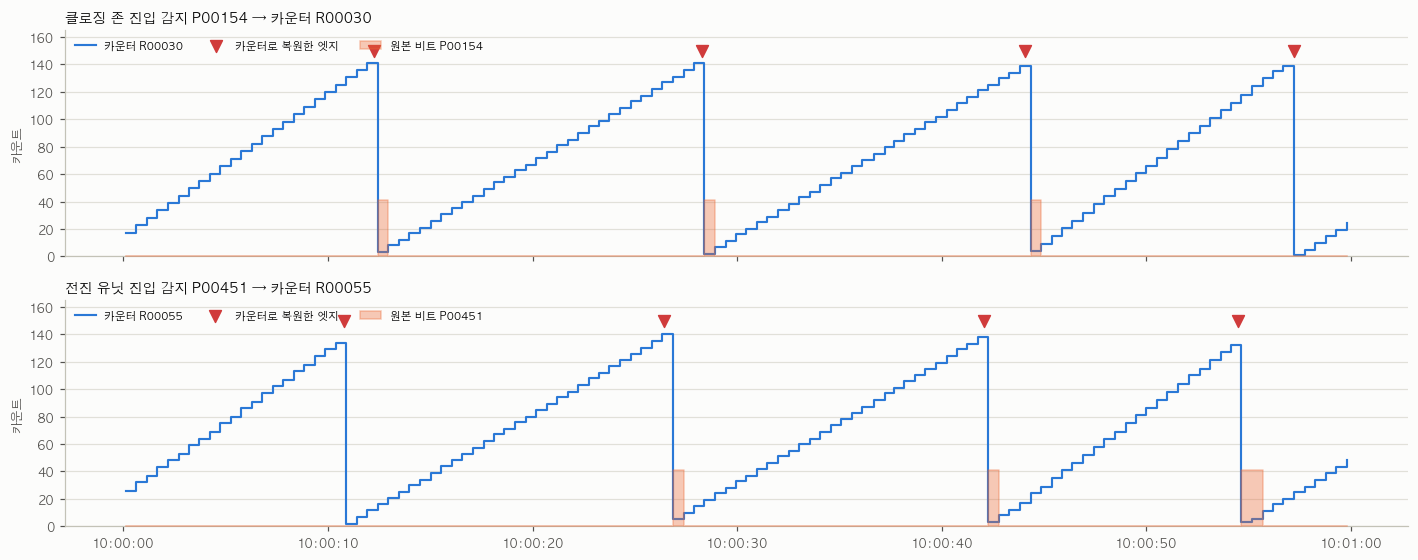

In [4]:
def plot_reset_window(ax, d, counter, sensor, title, t0, sec=60):
    w = d[(d.index >= t0) & (d.index < t0 + pd.Timedelta(seconds=sec))]
    ev = counter_resets(d, counter)
    ev = ev[(ev.t_est >= t0) & (ev.t_est < t0 + pd.Timedelta(seconds=sec))]
    ax.step(w.index, w[counter], where="post", color=BLUE, lw=1.4, label=f"카운터 {counter}")
    ax2 = ax.twinx()
    ax2.fill_between(w.index, 0, w[sensor].fillna(0).gt(0), step="post", color=ORANGE, alpha=0.35,
                     label=f"원본 비트 {sensor}")
    ax2.set_ylim(0, 4)
    ax2.set_yticks([])
    for s in ("top", "right", "left", "bottom"):
        ax2.spines[s].set_visible(False)
    ax.scatter(ev.t_est, np.full(len(ev), 150), marker="v", s=60, color=CRITICAL, zorder=5,
               label="카운터로 복원한 엣지")
    ax.set_ylim(0, 165)
    ax.set_ylabel("카운트", color=INK2, fontsize=8)
    ax.set_title(title, color=INK, fontsize=9, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    style_ax(ax)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left", ncol=3, frameon=False)


DAY_DEMO = "2026-10-16"
T0 = pd.Timestamp(f"{DAY_DEMO} 10:00:00")
demo = {g: add_position(load_group(g, DAY_DEMO)) for g in ["closing", "md_fwd"]}

fig, axes = plt.subplots(2, 1, figsize=(13, 5.2), facecolor=SURFACE, sharex=True)
plot_reset_window(axes[0], demo["closing"], "R00030", "P00154", "클로징 존 진입 감지 P00154 → 카운터 R00030", T0)
plot_reset_window(axes[1], demo["md_fwd"], "R00055", "P00451", "전진 유닛 진입 감지 P00451 → 카운터 R00055", T0)
plt.tight_layout()
plt.show()

---
## §4. 원본 엣지 vs 카운터 리셋 — 기간 전체 (H1)

기준 센서 6개에 대해 날마다
- **카운터 리셋 수** (= 복원한 엣지 수, 대차 통과 수와 같아야 함)
- **원본 비트 상승엣지 수** (DB 에 남은 것)
- **피치**: 같은 센서의 연속 엣지 사이 거리 (카운트). 중앙값과 흔들림(std, 120–160 범위 안)
- **속도 비율**: 초당 카운트 ÷ (Hz_In_Conv/10), `main` 그룹 정속 구간에서 행마다 Hz 로 가중해 계산

을 센다. 계산 결과는 `cache/conv_feat/daily_ref_sensor_stats.pkl` 에 저장해 두고 다시 쓴다.

In [5]:
STATS_PATH = os.path.join(FEAT_DIR, "daily_ref_sensor_stats.pkl")


def day_stats(day):
    out, loaded = [], {}
    for g, c, s, name in REF_SENSORS:
        if g not in loaded:
            raw = load_group(g, day)
            loaded[g] = add_position(raw) if len(raw) else None
        d = loaded[g]
        if d is None or c not in d or s not in d:
            continue
        ev = counter_resets(d, c)
        rises = int((bit_edges(d, s).edge == 1).sum())
        p = ev.pitch[(ev.pitch > 120) & (ev.pitch < 160)]
        row = {"day": day, "sensor": name, "group": g, "counter": c, "bit": s,
               "resets": len(ev), "raw_rises": rises,
               "pitch_med": p.median(), "pitch_std": p.std(), "pitch_out": int(ev.pitch.notna().sum() - len(p))}
        if g == "main":
            # 정속 구간만: Hz 가 최근 20샘플(약 10초) 동안 그대로이고 감속·정지 중이 아님. 가감속 구간은 지령과 실제가 다르다
            hz = d.Hz_In_Conv
            steady = hz.rolling(20).std().eq(0) & d.Conv_Run_Slow.fillna(0).eq(0) & d.Conv_Brake_Time.fillna(0).gt(0)
            m = run_mask(d) & d.dt.lt(1.0) & d.dpos.gt(0) & hz.gt(0) & steady
            row["speed_ratio"] = d.dpos[m].sum() / (d.dt * hz / 10)[m].sum()   # 행마다 Hz 로 가중
            row["run_hours"] = d.dt[run_mask(d) & d.dt.lt(1.0)].sum() / 3600
        out.append(row)
    return out


if os.path.exists(STATS_PATH):
    stats = pd.read_pickle(STATS_PATH)
else:
    rows_ = []
    for i, day in enumerate(DAYS, 1):
        rows_ += day_stats(day)
    stats = pd.DataFrame(rows_)
    stats["day"] = pd.to_datetime(stats["day"])
    stats.to_pickle(STATS_PATH)
stats["capture_%"] = stats.raw_rises / stats.resets * 100
stats.head(8)

,day,sensor,group,counter,bit,resets,raw_rises,pitch_med,pitch_std,pitch_out,speed_ratio,run_hours,capture_%
0,2026-09-10,대차 진입,main,R00040,P00140,4495,2545,139.0,1.398275,0,0.274475,16.241872,56.618465
1,2026-09-10,대차 쉬프트,main,R00080,P00141,4494,2486,139.0,1.401710,0,0.274475,16.241872,55.318202
2,2026-09-10,오프닝 진입,opening,R00070,P00164,4495,2648,139.0,2.082473,0,NaN,NaN,58.909900
3,2026-09-10,클로징 진입,closing,R00030,P00154,4494,2668,139.0,1.368238,0,NaN,NaN,59.368046
4,2026-09-10,전진 진입,md_fwd,R00055,P00451,4495,3563,139.0,8.803346,0,NaN,NaN,79.265851
5,2026-09-10,후진 진입,md_rev,R00060,P00459,4494,2855,139.0,4.066460,0,NaN,NaN,63.529150
6,2026-09-11,대차 진입,main,R00040,P00140,4487,2568,139.0,1.400828,0,0.274479,16.060090,57.232004
7,2026-09-11,대차 쉬프트,main,R00080,P00141,4486,2518,139.0,1.400738,0,0.274479,16.060090,56.130183


In [6]:
prod = stats[stats.resets >= 500]           # 대차가 500대 이상 지나간 날만 (가동일)
tab = prod.groupby("sensor").agg(
    가동일=("day", "nunique"),
    하루_엣지_중앙=("resets", "median"),
    원본_포착률_중앙=("capture_%", "median"),
    원본_포착률_최저=("capture_%", "min"),
    피치_중앙=("pitch_med", "median"),
    피치_흔들림_중앙=("pitch_std", "median"),
    피치_흔들림_최대=("pitch_std", "max"),
).reindex([s[3] for s in REF_SENSORS]).round(1)
tab

,가동일,하루_엣지_중앙,원본_포착률_중앙,원본_포착률_최저,피치_중앙,피치_흔들림_중앙,피치_흔들림_최대
sensor,,,,,,,
대차 진입,31,4441.0,54.8,51.6,139.0,1.4,1.6
대차 쉬프트,31,4441.0,55.8,53.9,139.0,1.4,1.7
오프닝 진입,31,4441.0,60.3,57.8,139.0,2.1,2.4
클로징 진입,31,4441.0,59.9,56.6,139.0,1.4,1.8
전진 진입,31,4441.0,77.3,73.6,139.0,8.1,9.1
후진 진입,31,4441.0,60.1,56.8,139.0,2.4,4.1


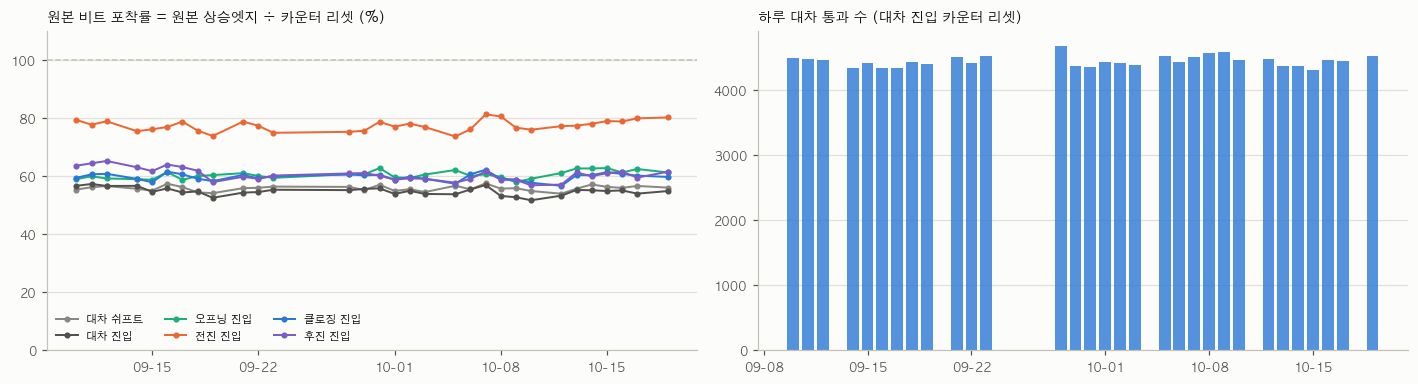

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), facecolor=SURFACE)
for name, g in prod.groupby("sensor"):
    axes[0].plot(g.day, g["capture_%"], marker="o", ms=3, lw=1.3, color=SENSOR_COLOR[name], label=name)
axes[0].axhline(100, color=AXIS, lw=1, ls="--")
axes[0].set_ylim(0, 110)
axes[0].set_title("원본 비트 포착률 = 원본 상승엣지 ÷ 카운터 리셋 (%)", color=INK, fontsize=9, loc="left")

e = prod[prod.sensor == "대차 진입"]
axes[1].bar(e.day, e.resets, color=BLUE, alpha=0.8, width=0.8)
axes[1].set_title("하루 대차 통과 수 (대차 진입 카운터 리셋)", color=INK, fontsize=9, loc="left")
for ax in axes:
    style_ax(ax)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].legend(fontsize=7, ncol=3, frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

---
## §5. 미리보기 — 피치 흔들림과 속도 비율 (H2, H3)

본격적인 추세 분석은 conv_03 에서 한다. 여기서는 기간 전체에서 **어느 센서가 튀는지**, **속도 비율이 일정한지**만 본다.

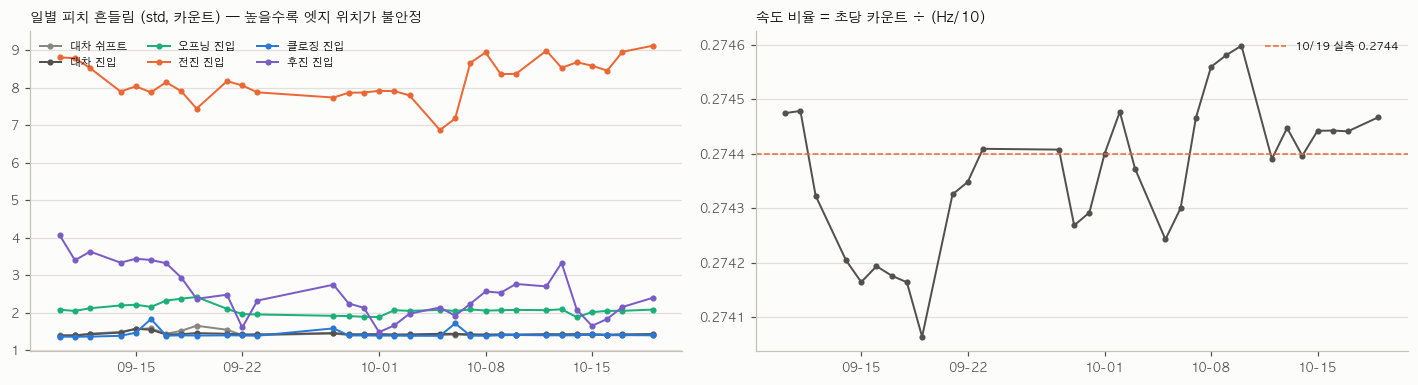

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), facecolor=SURFACE)
for name, g in prod.groupby("sensor"):
    axes[0].plot(g.day, g.pitch_std, marker="o", ms=3, lw=1.3, color=SENSOR_COLOR[name], label=name)
axes[0].set_title("일별 피치 흔들림 (std, 카운트) — 높을수록 엣지 위치가 불안정", color=INK, fontsize=9, loc="left")
axes[0].legend(fontsize=7, ncol=3, frameon=False, loc="upper left")

m = prod[prod.sensor == "대차 진입"]
axes[1].plot(m.day, m.speed_ratio, marker="o", ms=3, lw=1.3, color=INK2)
axes[1].axhline(K_SPEED, color=ORANGE, lw=1, ls="--", label=f"10/19 실측 {K_SPEED}")
axes[1].set_title("속도 비율 = 초당 카운트 ÷ (Hz/10)", color=INK, fontsize=9, loc="left")
axes[1].legend(fontsize=7, frameon=False)
for ax in axes:
    style_ax(ax)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout()
plt.show()

---
## §6. 정리

**데이터:** 7그룹 × 40일(09-10 – 10-19) 모두 캐시에 있다 (약 102 MB). 가동일은 31일이고, 쉰 날은 09-13 · 09-20 · 09-24 – 09-27(연휴) · 10-04 · 10-11 · 10-18 이다. 가동일 하루에 대차 약 4,440대가 지나간다.

| 가설 | 판정 | 근거 |
|---|---|---|
| **H1** 카운터가 모든 엣지를 남긴다 | **성립** | 기준 센서 6개 모두 하루 엣지 수가 같다(중앙 4,441). 원본 비트 포착률은 55–60%, 전진 진입만 77% (§4) |
| **H2** 피치 139, 흔들림 큰 센서가 이상 후보 | **성립, 후보 1개** | 6개 모두 피치 중앙 139. 흔들림: 대차 진입·쉬프트·클로징 1.4, 오프닝 2.1, 후진 2.4, **전진 8.1 (다른 센서의 4–6배)** (§5) |
| **H3** 속도 비율이 일정하다 | **성립** | 0.2744 ± 0.0001 (31일). 구동부 기준선으로 쓴다 (§5) |

**전진 진입 감지(P00451)에서 눈에 띄는 것**
- 피치 흔들림이 기간 내내 다른 센서보다 훨씬 크다. 센서가 대차를 감지하는 위치가 매번 몇 카운트씩 앞뒤로 흔들린다는 뜻이다.
- 원본 포착률이 높다(77%). 포착률은 센서가 켜져 있는 시간에 비례하므로, **P00451 은 다른 센서보다 오래 켜져 있다.** §3 그림에서도 펄스 폭이 1초 가까운 것이 보인다.
- **10-07 부터 한 단계 올라갔다:** 흔들림 7 안팎(10-05·10-06) → 8.4 – 9.1, 원본 상승엣지도 하루 약 3,370 → 3,500 – 3,670. 그날 설비에 손을 댔는지 확인할 필요가 있다.
- 후진 진입(P00459)도 9월 초에는 흔들림이 3.3 – 4.1 이었다가 09-19 이후 2 안팎으로 내려왔다.
- 아직 원인을 단정하지 않는다. 흔들림이 **특정 대차에서만** 나오면 대차(표식·지그) 문제, **모든 대차에 고르게** 나오면 센서(브래킷·감지 거리·오염) 문제다. conv_02 에서 대차별로 나눠 확인한다 (H5).

**다음 (conv_02):** 모든 센서 엣지를 "대차번호 × 카운트 위치" 이벤트 표로 만든다. 기준 센서 간 물리 거리(몇 대차 + 몇 카운트), 대차 지문(H4), P00451 흔들림의 대차 의존성(H5)을 본다.